# Phosphosite Analysis — UMAP Figure

UMAP of STRING phosphosite subgraph, colored by Louvain community.

This notebook is a trimmed subset of `fig1c_phosphosite_functional_analysis.ipynb`, containing only the code required to generate the UMAP panel.

## 0. Imports & paths

In [ ]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from adjustText import adjust_text
import umap

sig_sites_f    = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_res.csv"
phospho_data_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/stat_results_IL6IL10phosphopairwiseBMDMheatmap.csv"
expressed_tf_f = "/ix/djishnu/Aaron_F/Cleaned_Proteomics_Aaron/20240906/TF_enrichment/Results/log2_thresh_2.5_expressed_tfs.txt"
string_net_f   = "/ix/djishnu/Aaron_F/proteomics_proj/Results/phosphoNetwork_res/out_files/string_DES_gene_pairwise_interactions.tsv"
out_path       = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig1/umap_communities"

fig_out = f"{out_path}/figures"
os.makedirs(fig_out, exist_ok=True)
os.makedirs(f"{out_path}/out_files", exist_ok=True)
print(f"Output directory: {fig_out}")

Output directory: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig1c/figures


## 1. Load & preprocess data

In [2]:
sig_sites = pd.read_csv(sig_sites_f)
sig_sites['geneSymbol'] = sig_sites['id'].str.split('_').str[0]
sig_sites['id']         = sig_sites['id'].str.split('_', n=1).str[1]
sig_sites_list          = sig_sites.id.tolist()

prot_df = pd.read_csv(phospho_data_f)
prot_df['geneSymbol'] = prot_df['id'].str.split('_').str[0]
prot_df['id']         = prot_df['id'].str.split('_', n=1).str[1]
prot_df = prot_df[["id", "geneSymbol", "VMsiteFlanks"]]

sig_prot_df = prot_df.loc[prot_df.id.isin(sig_sites_list)].copy().reset_index(drop=True)
expressed_tf = np.loadtxt(expressed_tf_f, dtype=str).tolist()
sig_prot_df["is_tf"]      = sig_prot_df.geneSymbol.isin(expressed_tf)
sig_prot_df["geneSymbol"] = sig_prot_df.geneSymbol.str.upper()

print(f"Significant phosphosites: {len(sig_prot_df)} | TF sites: {sig_prot_df.is_tf.sum()}")

Significant phosphosites: 1220 | TF sites: 106


## 2. Build STRING PPI subgraph & Louvain communities

In [3]:
string_net = pd.read_csv(string_net_f, sep="\t")
string_net["node1"] = string_net.node1.str.upper()
string_net["node2"] = string_net.node2.str.upper()

genes_of_interest = set(sig_prot_df["geneSymbol"].unique())
subgraph_edges = (
    string_net[["node1", "node2"]]
    .rename(columns={"node1": "source_genesymbol", "node2": "target_genesymbol"})
    .assign(interaction=1)
    .loc[lambda df:
         df.source_genesymbol.isin(genes_of_interest) &
         df.target_genesymbol.isin(genes_of_interest)]
    .reset_index(drop=True)
)

G = nx.from_pandas_edgelist(
    subgraph_edges,
    source="source_genesymbol",
    target="target_genesymbol",
    edge_attr="interaction",
    create_using=nx.DiGraph()
)
G_und = G.to_undirected()
print(f"STRING subgraph — Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")

communities = nx.community.louvain_communities(G_und, seed=42)
communities = sorted(communities, key=len, reverse=True)

node_to_comm = {node: i for i, comm in enumerate(communities) for node in comm}
nx.set_node_attributes(G, node_to_comm, name="community")

focal_tfs = set(sig_prot_df.loc[sig_prot_df.is_tf, "geneSymbol"].str.upper())
sig_genes  = set(sig_prot_df["geneSymbol"].str.upper().unique())

large_communities = [i for i, comm in enumerate(communities) if len(comm) > 50]
large_comm_nodes  = {n for i in large_communities for n in communities[i]}

palette      = plt.cm.tab20.colors
comm_palette = {comm_idx: palette[i % len(palette)]
                for i, comm_idx in enumerate(large_communities)}

print(f"\nTotal communities: {len(communities)}")
for i, comm in enumerate(communities):
    tfs_in = sorted([n for n in comm if n in focal_tfs])
    print(f"Community {i:>2} | {len(comm):>3} nodes | TFs ({len(tfs_in)}): {tfs_in}")

STRING subgraph — Nodes: 721, Edges: 6806

Total communities: 19
Community  0 | 156 nodes | TFs (3): ['ARID5A', 'THAP4', 'ZFP91']
Community  1 | 145 nodes | TFs (29): ['AFF4', 'ARID1A', 'ARID3A', 'ARID4A', 'ARID5B', 'ARNTL', 'CREB1', 'ELMSAN1', 'ETV3', 'GABPA', 'HBP1', 'HMGA2', 'ID2', 'IKZF1', 'KLF2', 'LRRFIP1', 'MBD3', 'MECP2', 'MIER1', 'NCOR1', 'NFIL3', 'NR2C2', 'PBRM1', 'RERE', 'RREB1', 'TCF7L2', 'WDHD1', 'ZBTB21', 'ZFP28']
Community  2 | 113 nodes | TFs (9): ['BCLAF1', 'CDC5L', 'DNAJC2', 'GCFC2', 'HMGXB4', 'SON', 'ZFP318', 'ZFP36L1', 'ZFP36L2']
Community  3 | 101 nodes | TFs (12): ['ERF', 'IRF5', 'JUN', 'MEF2A', 'MEF2D', 'MLXIP', 'NFATC1', 'NFATC2', 'NFIC', 'NFKB2', 'STAT3', 'STAT6']
Community  4 |  81 nodes | TFs (6): ['ATF7', 'FOXO3', 'FOXO4', 'PLEK', 'TFE3', 'TFEB']
Community  5 |  35 nodes | TFs (0): []
Community  6 |  22 nodes | TFs (0): []
Community  7 |  22 nodes | TFs (1): ['FOXK1']
Community  8 |   7 nodes | TFs (0): []
Community  9 |   7 nodes | TFs (0): []
Community 10 |

## 3. UMAP of community structure

/ihome/djishnu/aaf92/.conda/envs/carnival_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


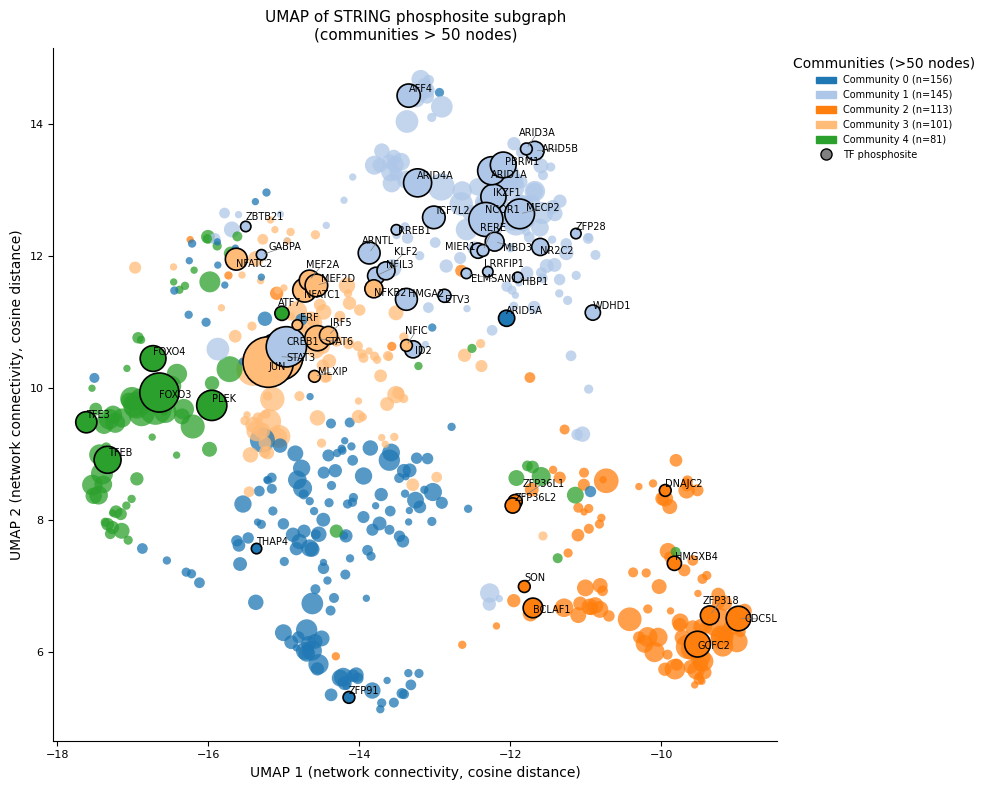

Saved UMAP.


In [4]:
nodes    = list(G_und.nodes())
node_idx = {n: i for i, n in enumerate(nodes)}
degrees  = dict(G_und.degree())

A         = nx.to_numpy_array(G_und, nodelist=nodes)
reducer   = umap.UMAP(n_neighbors=15, min_dist=0.3, metric="cosine", random_state=42)
embedding = reducer.fit_transform(A)

nodes_f      = [n for n in nodes if n in large_comm_nodes]
idx_f        = [node_idx[n] for n in nodes_f]
embedding_f  = embedding[idx_f]
comm_color_f = [palette[node_to_comm[n] % len(palette)] for n in nodes_f]
node_size_f  = [20 + 8 * degrees[n] for n in nodes_f]
tf_mask_f    = [i for i, n in enumerate(nodes_f) if n in focal_tfs]

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(embedding_f[:, 0], embedding_f[:, 1],
           c=comm_color_f, s=node_size_f, alpha=0.75, linewidths=0, zorder=2)
ax.scatter(embedding_f[tf_mask_f, 0], embedding_f[tf_mask_f, 1],
           c=[comm_color_f[i] for i in tf_mask_f],
           s=[node_size_f[i] * 2 for i in tf_mask_f],
           edgecolors="black", linewidths=1.2, zorder=3)

texts = []
for i in tf_mask_f:
    texts.append(ax.text(embedding_f[i, 0], embedding_f[i, 1], nodes_f[i], fontsize=7, zorder=4))
adjust_text(texts, x=embedding_f[tf_mask_f, 0], y=embedding_f[tf_mask_f, 1],
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
            expand_points=(1.5, 1.5), force_points=0.5)

legend_handles = [
    mpatches.Patch(color=palette[i % len(palette)],
                   label=f"Community {i} (n={len(communities[i])})")
    for i in large_communities
] + [Line2D([0], [0], marker='o', color='w', markerfacecolor='grey',
            markeredgecolor='black', markersize=8, label='TF phosphosite')]
ax.legend(handles=legend_handles, fontsize=7, loc='upper left',
          bbox_to_anchor=(1.01, 1), frameon=False, title="Communities (>50 nodes)")
ax.set_title("UMAP of STRING phosphosite subgraph\n(communities > 50 nodes)", fontsize=11)
ax.set_xlabel("UMAP 1 (network connectivity, cosine distance)", fontsize=10)
ax.set_ylabel("UMAP 2 (network connectivity, cosine distance)", fontsize=10)
ax.tick_params(labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(f"{fig_out}/umap_communities_large.png", bbox_inches='tight', dpi=300)
plt.savefig(f"{fig_out}/umap_communities_large.svg", bbox_inches='tight', dpi=300)
plt.show()
print("Saved UMAP.")